# 0.5. Временное разрешение CO₂: 15-минутные наблюдения и двухчасовые средние

Dimitri Bolt · 02.11.2026 · предложение для I.G.

## 1. Научный вопрос и предлагаемый подход

I.G. поставил вопрос: достаточно ли двухчасового временного разрешения для исследования относительных Fourier-фаз CO₂? Я проверяю два различных следствия укрупнения сетки: изменение представления наблюдаемых концентраций и изменение разности Fourier-фаз на суточной частоте. В соответствии с моим решением от 02.11.2026 я использую **окна 14 суток с шагом 1 сутки**; прежние результаты для 30-суточных окон сохраняю как исторические.

Я использую принятые наблюдения **LEO West W_x1_y4, x=1 м, y=4 м**, на глубинах **5, 20 и 50 см** (GMM222 996, 1012 и 1035), за период **[01.05.2025 00:00, 01.10.2026 00:00)**. При сравнении концентраций я сохраняю собственный набор наблюдений каждого датчика. При сравнении фаз я сначала фиксирую пересечение занятых 15-минутных ячеек всех трёх датчиков и использую ровно эти исходные наблюдения в обоих представлениях. Я сохраняю пропуски без интерполяции. Временные метки остаются в шкале базы данных `LOCALDATETIME`; её часовой пояс не установлен.

[Утверждённый план исследования](PLAN.md#preparation) · [Историческое сравнение](00_preliminary_fourier_phases.ipynb#temporal-grid-resolution).

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'Project_description/sensorDB/preliminary_fourier_phases.py').exists())
sys.path.insert(0, str(ROOT / 'Project_description/sensorDB'))
import preliminary_fourier_phases as phases
OUT = phases.TEMPORAL_OUT
concentration, phase_summary, diagnostics, examples = phases.load_temporal_resolution()
def figure(name):
    display(Image(filename=str(OUT / (name + '.jpg')), width=1400))

## 2. Как я усредняю 15-минутные измерения до двух часов

Для каждого датчика отдельно я вычисляю среднее по фактическим принятым наблюдениям в полуоткрытой календарной ячейке $b=[s,s+2\,\mathrm{h})$. Для сравнения я сопоставляю это среднее только с исходными моментами наблюдений:

$$\overline C_b=\frac{1}{n_b}\sum_{t\in b}C_t,\qquad
\widetilde C_t=\overline C_{b(t)},\qquad e_t=C_t-\widetilde C_t.$$

Здесь я обозначаю через $s$ начало ячейки, через $n_b$ — число принятых наблюдений в ней, через $C_t$ — исходную концентрацию в момент $t$, а через $b(t)$ — содержащую этот момент ячейку. Величина $\overline C_b$ — средняя концентрация в ячейке; $\widetilde C_t$ — это среднее, сопоставленное с моментом исходного наблюдения; $e_t$ — остаток, то есть отклонение наблюдения от среднего. Все три концентрационные величины и остаток выражаю в ppm.

Я не создаю значений в отсутствующие моменты наблюдений. Занятая двухчасовая ячейка может содержать менее восьми наблюдений. Среднее может сохранить вклад краткого отклонения, но утратить сведения о его времени, экстремумах и внутренней форме.

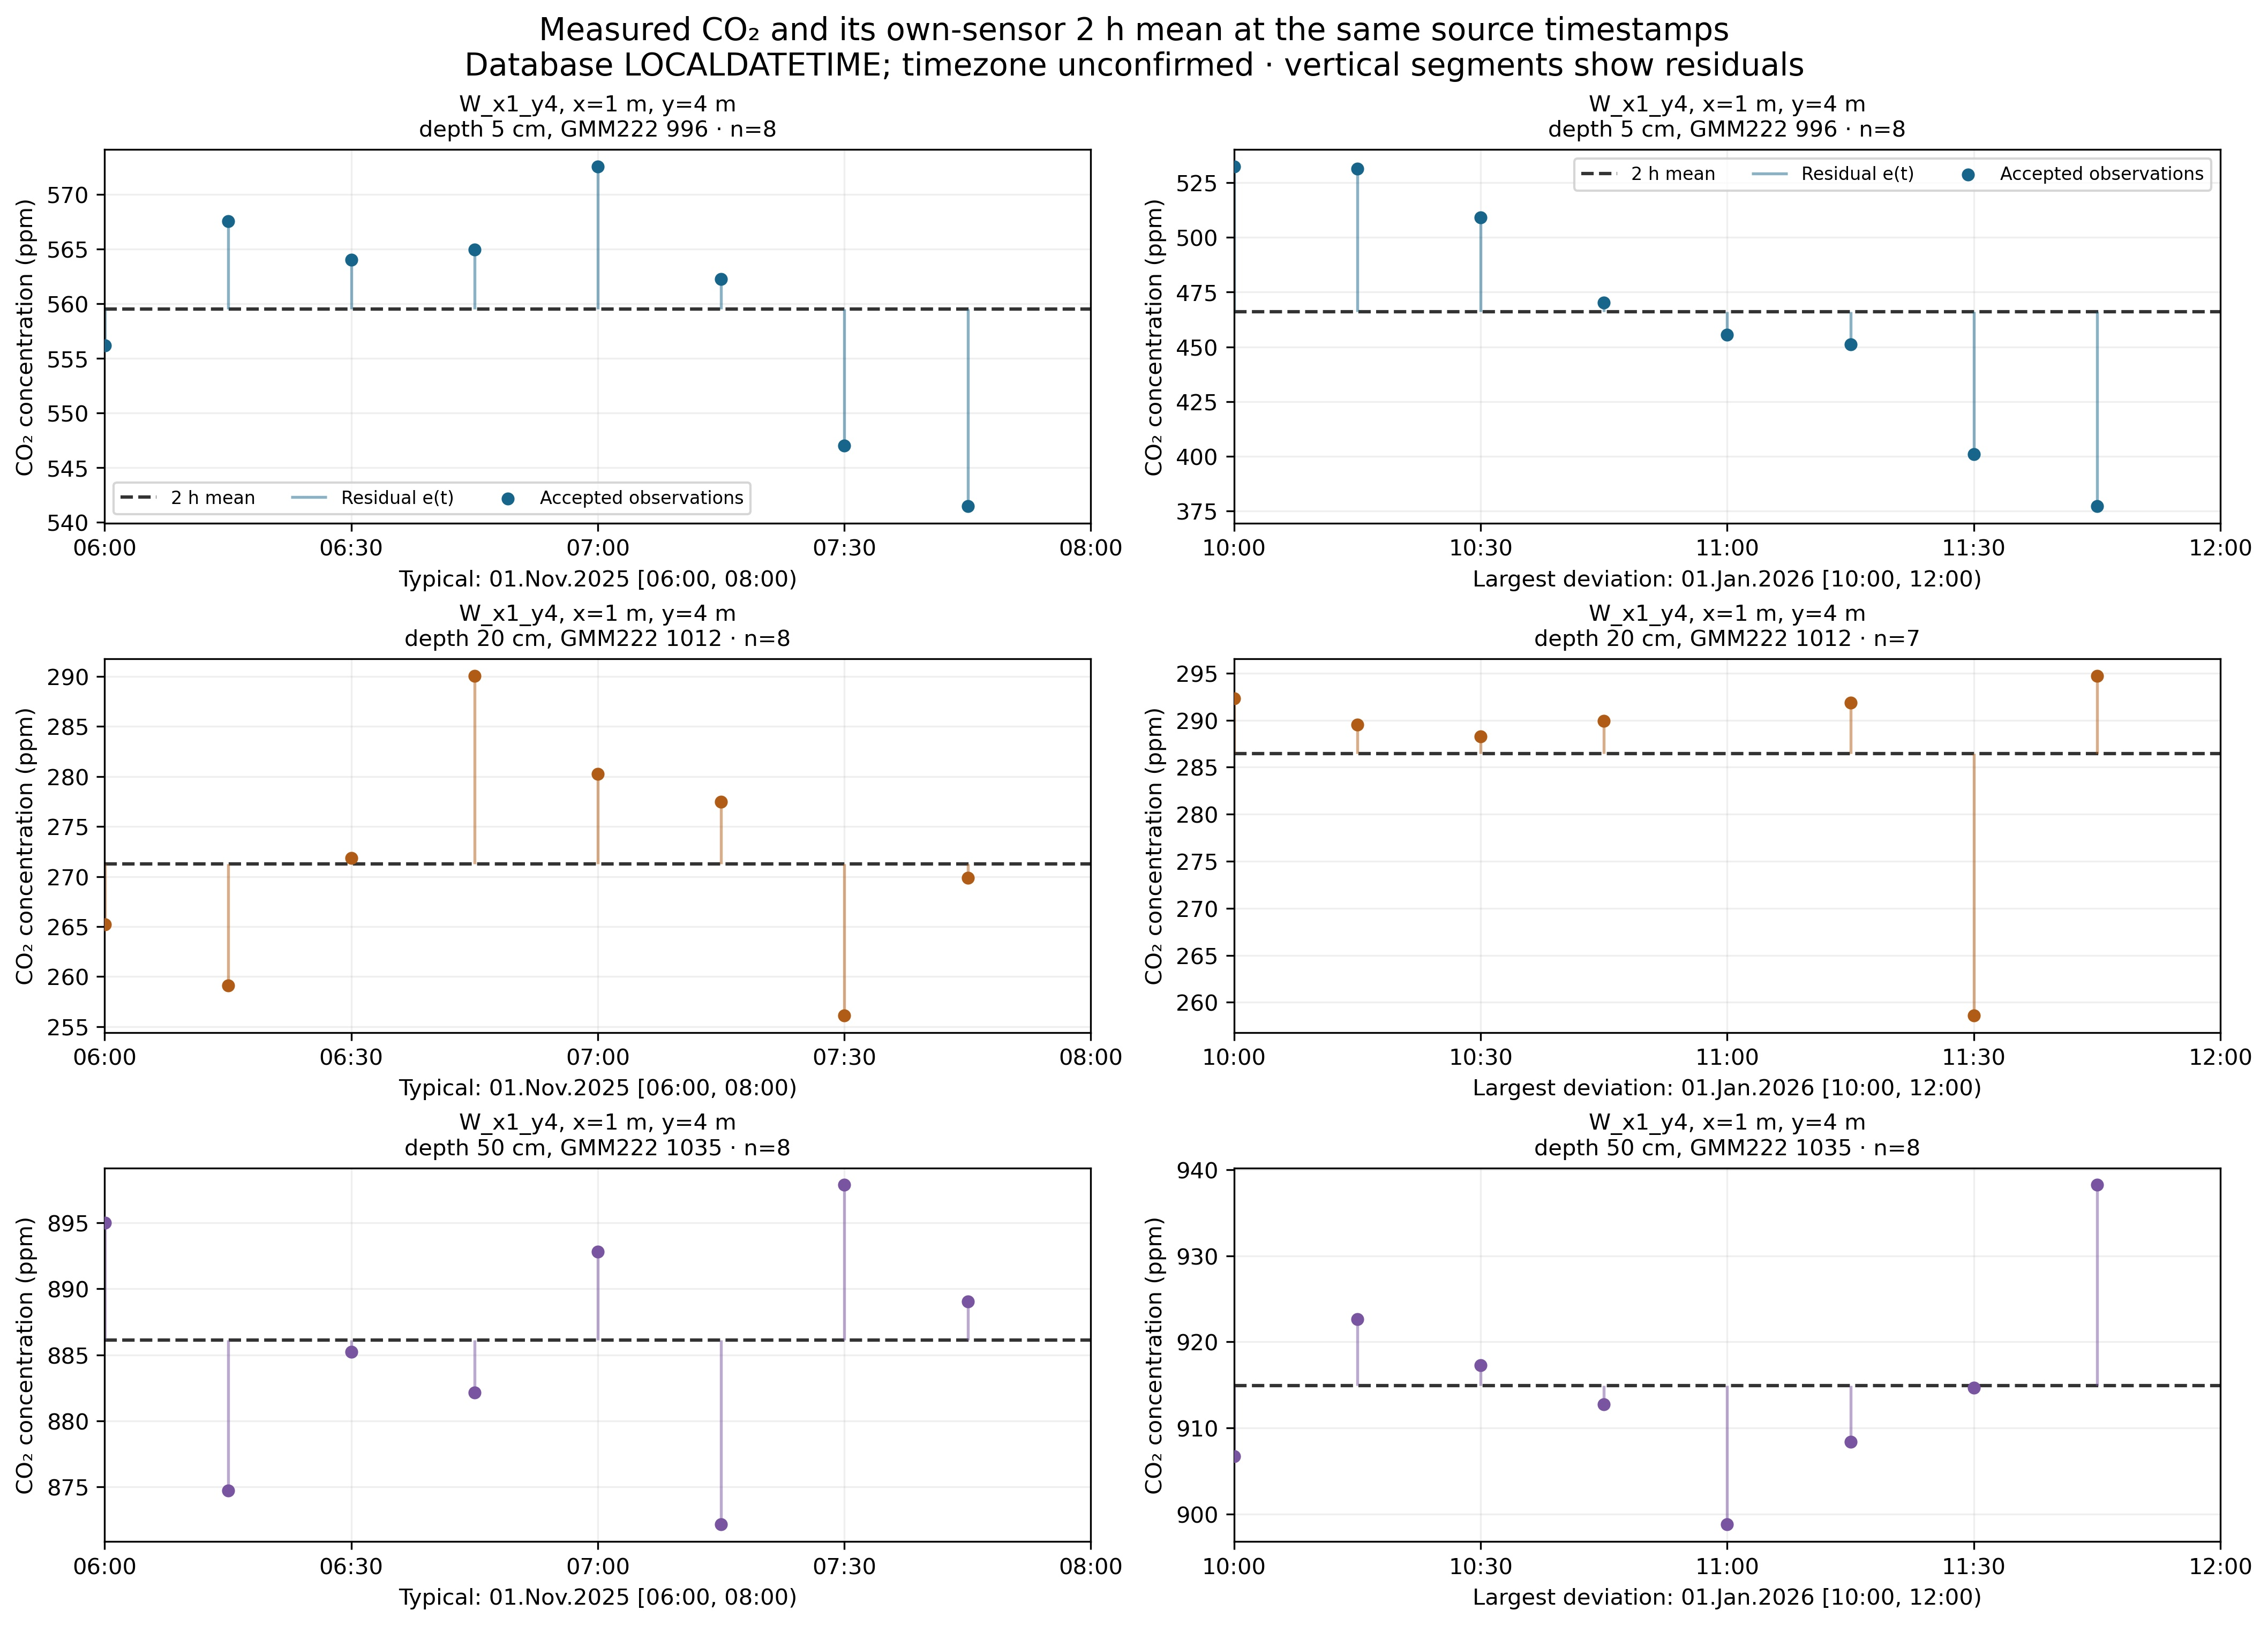

In [2]:
figure('concentration_examples')

**Рисунок 1.** Я показываю наблюдаемую концентрацию CO₂ точками, двухчасовое среднее — пунктиром, а остатки — вертикальными отрезками. Строки сверху вниз соответствуют глубинам 5, 20 и 50 см; в каждой панели указаны датчик и координаты. Вертикальные масштабы различаются. В левом столбце я показываю интервал **01.11.2025 06:00–08:00**, выбранный по RMSE двухчасовой ячейки на глубине 5 см, ближайшему к медиане RMSE ячеек этого датчика. В правом столбце — **01.01.2026 10:00–12:00**, выбранный по наибольшему абсолютному отклонению на глубине 5 см; при точном равенстве я выбираю самую раннюю ячейку. На всех трёх глубинах я показываю одни и те же интервалы. «Типичный» относится к этому правилу выбора на глубине 5 см, а не ко всем датчикам. На панелях я сопоставляю положение точек с горизонтальным средним: вертикальные отрезки показывают отклонения, которые исчезают при замене наблюдений средним. Тем самым рисунок иллюстрирует потерю внутридвухчасовой детализации. Линию среднего я не трактую как наблюдаемую траекторию. [JPG для печати](output/temporal_resolution_15min_vs_2h/concentration_examples.jpg).

## 3. Сравнение концентраций: MAE и RMSE

Я сравниваю значения в одни и те же фактические исходные моменты времени и придаю каждому наблюдению одинаковый вес:

$$\mathrm{MAE}_C=\frac{1}{N}\sum_{t=1}^{N}|e_t|,\qquad
\mathrm{RMSE}_C=\sqrt{\frac{1}{N}\sum_{t=1}^{N}e_t^2}.$$

Здесь $N$ — число принятых исходных наблюдений данного датчика, а $t$ в сумме нумерует эти наблюдения. Через $\mathrm{MAE}_C$ я обозначаю среднее абсолютное отклонение, через $\mathrm{RMSE}_C$ — корень из среднего квадрата отклонений; обе величины выражаю в ppm.

В сравнение я включаю **49,311 / 49,293 / 49,267** наблюдений на глубинах 5 / 20 / 50 см соответственно. Сумма остатков внутри каждой ячейки равна нулю с учётом численной точности. Поэтому стандартное отклонение остатков с делением на $N$ совпадает с RMSE; избыточную метрику я не ввожу. В следующей таблице Depth означает глубину, Sensor — датчик; столбцы MAE и RMSE содержат определённые выше показатели.

,Depth,Sensor,MAE (ppm),RMSE (ppm)
0,5 cm,GMM222 996,8.558477,10.974238
1,20 cm,GMM222 1012,7.874951,9.920604
2,50 cm,GMM222 1035,6.975188,8.745322


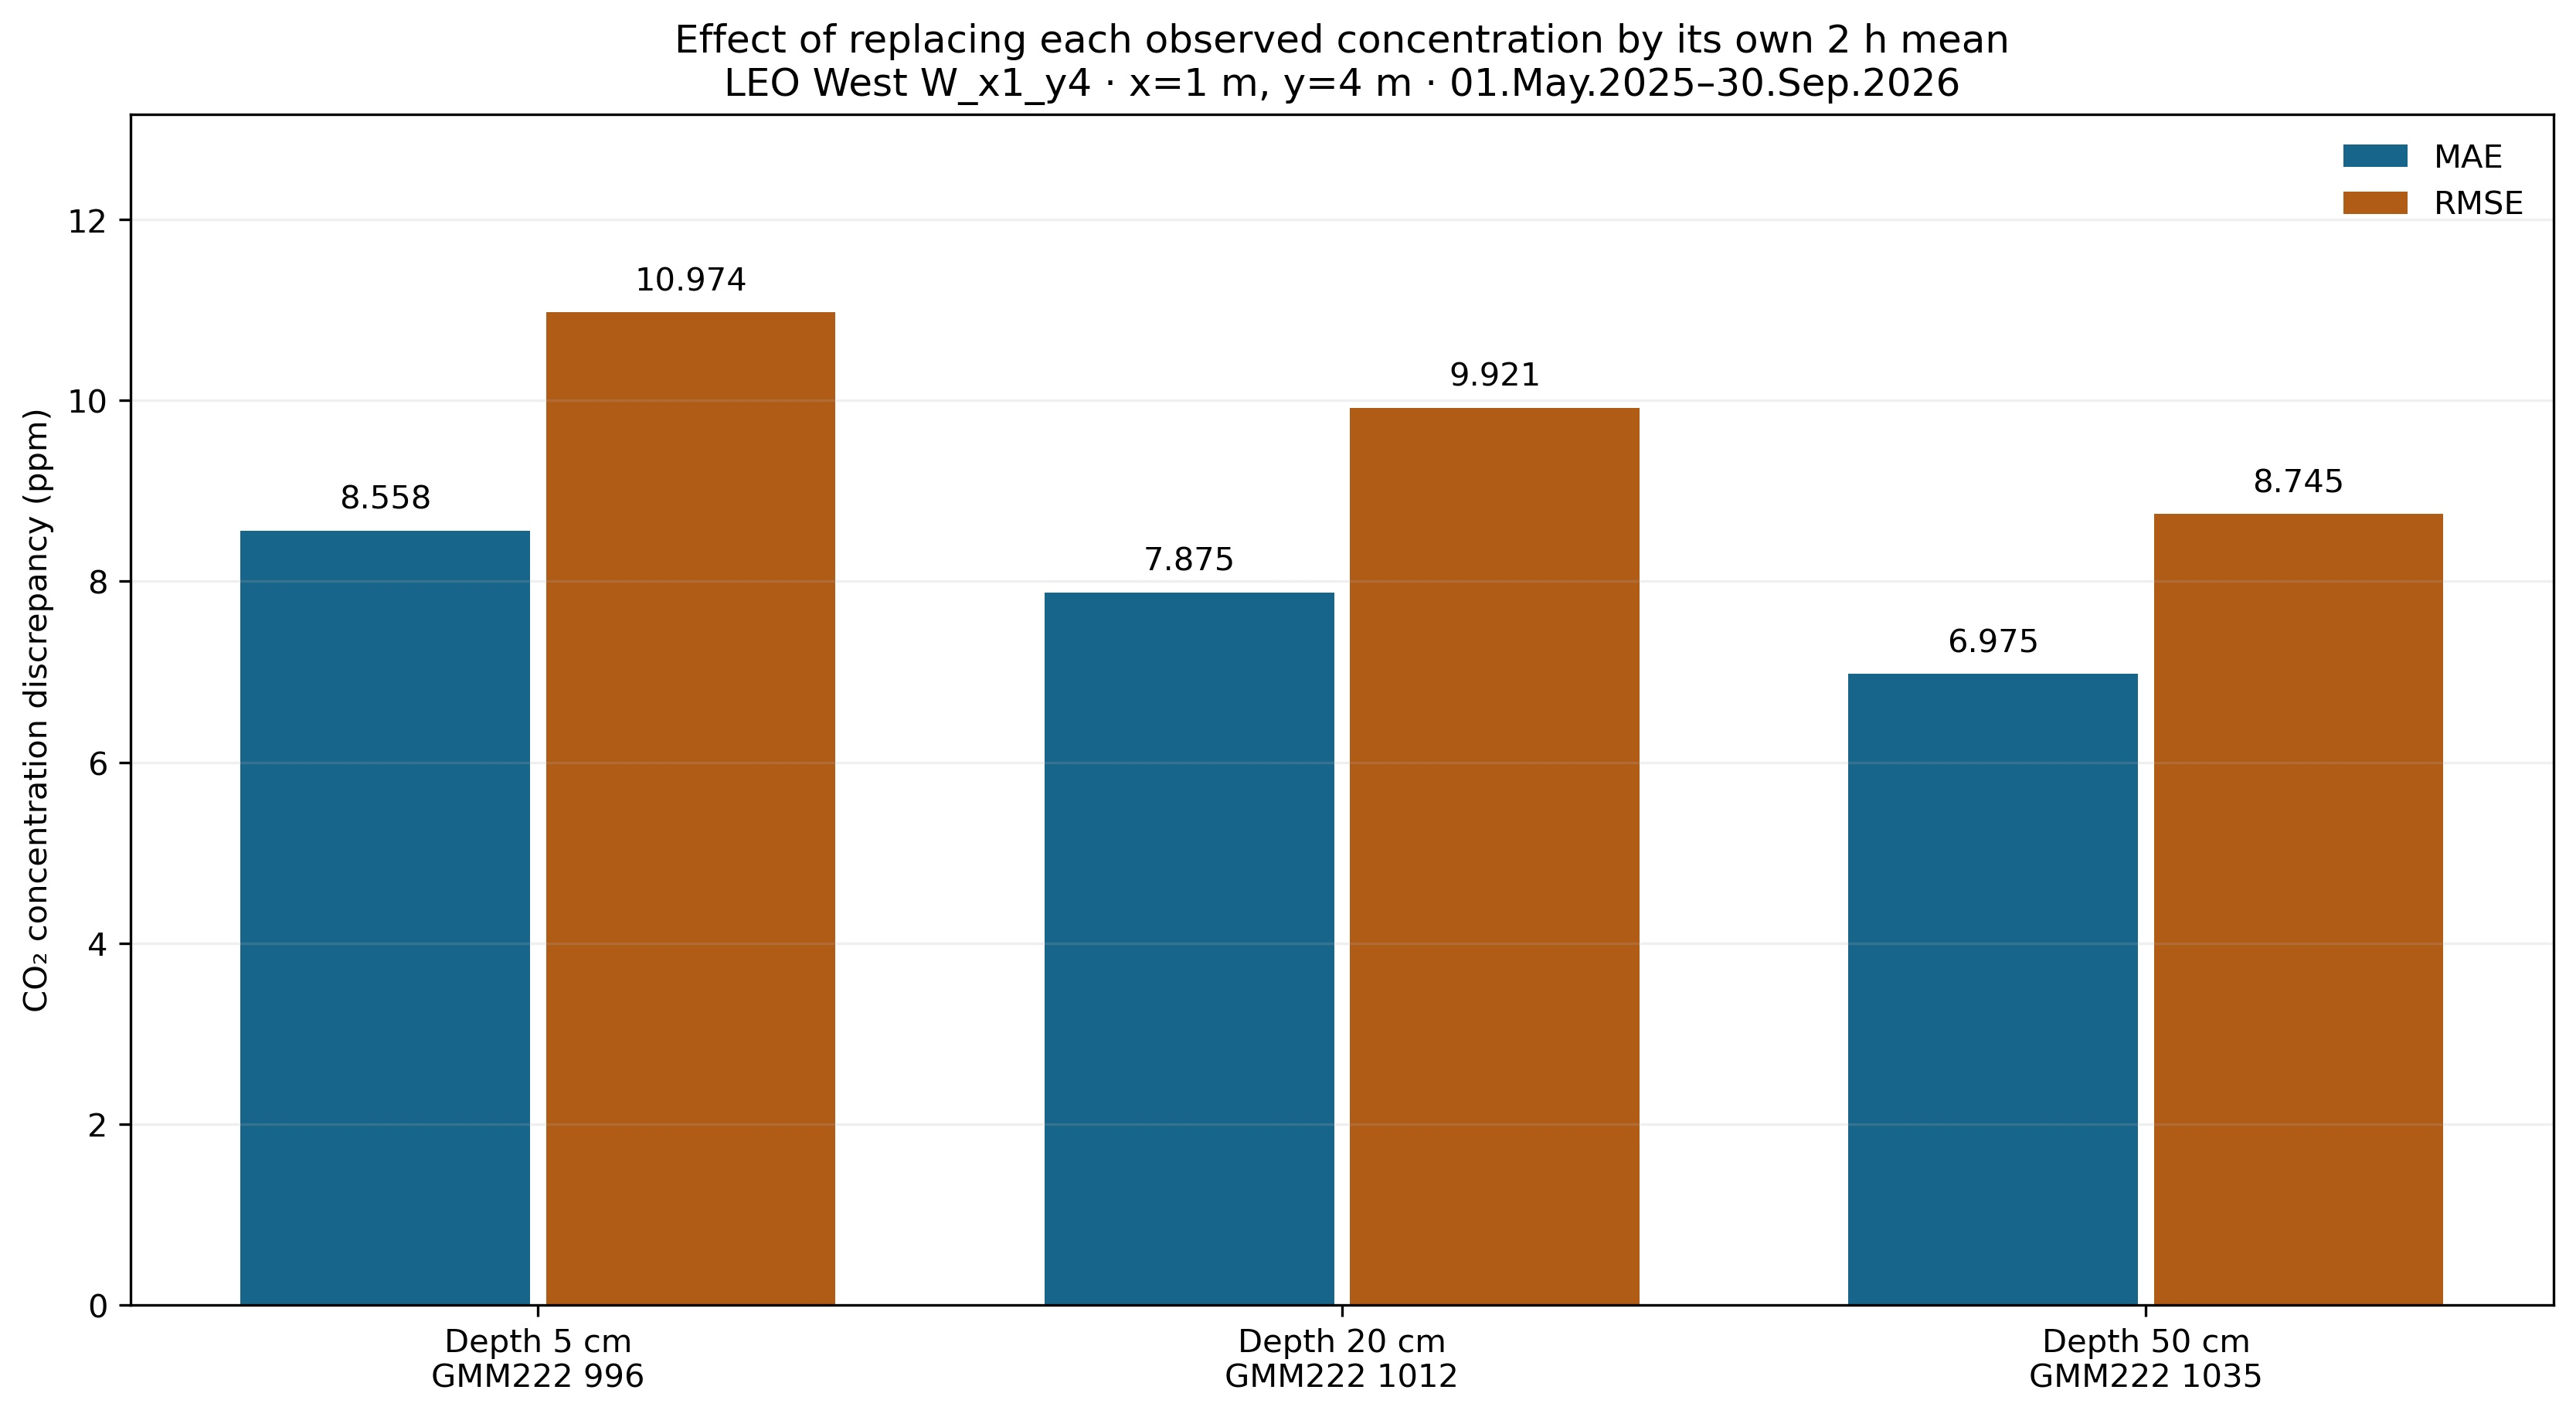

In [3]:
display(concentration.assign(Depth=['5 cm', '20 cm', '50 cm'],
    Sensor=['GMM222 996', 'GMM222 1012', 'GMM222 1035'])[
    ['Depth', 'Sensor', 'MAE_ppm', 'RMSE_ppm']].rename(columns={
    'MAE_ppm':'MAE (ppm)', 'RMSE_ppm':'RMSE (ppm)'}).round(6))
figure('concentration_errors')

**Рисунок 2.** Для каждой глубины я показываю рядом два столбца: MAE и RMSE, согласно легенде. Сопоставление столбцов MAE между глубинами показывает, что замена реального наблюдения его двухчасовым средним изменяет значение **в среднем по модулю на 8.558 / 7.875 / 6.975 ppm** на глубинах 5 / 20 / 50 см. Соответствующие значения RMSE равны **10.974 / 9.921 / 8.745 ppm**; возведение в квадрат придаёт большим отклонениям больший вес. Эти показатели я интерпретирую как расхождения, обусловленные представлением данных, а не как ошибки измерения относительно неизвестной истинной концентрации. Рисунок количественно подтверждает потерю детализации, показанную на рисунке 1. В полной таблице я сохраняю также 95-е процентили и максимумы. [JPG для печати](output/temporal_resolution_15min_vs_2h/concentration_errors.jpg).

**Вывод по концентрации.** Двухчасовые средние сохраняют среднее значение ячейки, но не воспроизводят исходные концентрации внутри неё. Поэтому я сохраняю исходные 15-минутные наблюдения, даже если для фазового анализа использую более грубую сетку.

### 3.1. Масштаб отклонений относительно наблюдаемого суточного размаха

Чтобы придать MAE понятный масштаб, я для каждого датчика отдельно сравниваю его с характерным размахом исходных концентраций за календарные сутки. Я использую те же принятые исходные наблюдения, из которых были получены собственные двухчасовые средние датчика, без ограничения пересечением трёх каналов:

$$D_d=\max_{t\in d}C_t-\min_{t\in d}C_t,\qquad
D_{\mathrm{typ}}=\mathrm{median}_d D_d,\qquad
R=\frac{\mathrm{MAE}_C}{D_{\mathrm{typ}}}.$$

Здесь $d$ — полуоткрытый календарный интервал от полуночи до следующей полуночи в исходной шкале `LOCALDATETIME`; $D_d$ — наблюдаемый размах за этот день, а $D_{\mathrm{typ}}$ — медиана определённых суточных размахов с равным весом каждого дня. Обе величины выражаю в ppm. Безразмерное $R$ сопоставляет ранее сохранённый MAE за весь период с этой медианой. **Это отношение двух характеристик масштаба, а не точная доля потерянной суточной изменчивости.** Суточный размах включает все наблюдаемые изменения внутри календарного дня и не выделяет отдельно суточную гармонику.

При менее чем двух наблюдениях я оставляю размах неопределённым. Полноту описываю числом занятых 15-минутных ячеек из 96; полным называю день, в котором заняты все 96 ячеек. Это описание покрытия, не новая маска качества. Во всех **518 днях каждого датчика** здесь достаточно наблюдений: на глубине 5 см имеется 90–96 отсчётов в день (93.75–100% ячеек), на глубинах 20 и 50 см — 91–96 (94.79–100%). Подробные числа по каждому дню, включая начальные и конечные пропуски, я сохраняю в [суточной таблице](output/temporal_resolution_15min_vs_2h/daily_scale/daily_ranges.csv).

В таблице ниже я показываю основной результат по всем дням. Координаты относятся к W_x1_y4, датчики — GMM222.

In [4]:
daily_scale, daily_sensitivity, daily_counts = phases.load_daily_concentration_scale()
display(daily_scale.assign(
    channel=['5 см · 996', '20 см · 1012', '50 см · 1035'],
    coordinates='x=1 м, y=4 м',
    days_coverage=[f'{int(r.days)}; полных {int(r.full_days)}; n={int(r.n_min)}–{int(r.n_max)}/96'
                   for r in daily_scale.itertuples()])[
    ['channel','coordinates','MAE_ppm','D_typ_ppm','R','days_coverage']].rename(columns={
    'channel':'Глубина · датчик', 'coordinates':'W_x1_y4', 'MAE_ppm':'MAE (ppm)',
    'D_typ_ppm':'Типичный суточный размах (ppm)', 'R':'R', 'days_coverage':'Дни и покрытие'}).round(6))

,Глубина · датчик,W_x1_y4,MAE (ppm),Типичный суточный размах (ppm),R,Дни и покрытие
0,5 см · 996,"x=1 м, y=4 м",8.558477,104.788717,0.081674,518; полных 246; n=90–96/96
1,20 см · 1012,"x=1 м, y=4 м",7.874951,65.868386,0.119556,518; полных 219; n=91–96/96
2,50 см · 1035,"x=1 м, y=4 м",6.975188,48.656310,0.143356,518; полных 227; n=91–96/96


**Чувствительность к полноте покрытия.** Я отдельно сопоставил все дни, полные дни и неполные дни; разбивку по точному числу наблюдений также сохранил. Полных дней на глубинах 5 / 20 / 50 см — **246 / 219 / 227**, неполных — **272 / 299 / 291**. Если для знаменателя использовать только полные дни, медианы размахов равны **108.208417 / 66.825784 / 48.732913 ppm**, а отношения при том же глобальном MAE — **0.079093 / 0.117843 / 0.143131**. Для неполных дней медианы равны **101.954524 / 65.431560 / 48.595060 ppm**, а отношения — **0.083944 / 0.120354 / 0.143537**. Таким образом, сравнение полных дней со всеми днями даёт для 5 см около 7.91% вместо 8.17%, для 20 см — 11.78% вместо 11.96%, для 50 см — 14.31% вместо 14.34%.

Я сохраняю основной результат по всем определённым дням и не исключаю неполные дни новой маской. Эти группы охватывают разные календарные даты, поэтому различие медиан не измеряет отдельно причинный эффект пропусков. Пропущенные наблюдения могут скрывать экстремумы. [Сравнение групп по покрытию](output/temporal_resolution_15min_vs_2h/daily_scale/daily_coverage_sensitivity.csv) · [разбивка по числу наблюдений](output/temporal_resolution_15min_vs_2h/daily_scale/daily_coverage_counts.csv).

Для суточной иллюстрации я использую заданный день **01.11.2025** на глубине 5 см: он содержит **96/96** отсчётов и показанный ранее двухчасовой пример 06:00–08:00. Поэтому замена дня не требуется. На рисунке я отделяю реальные значения этого дня от статистик всего периода.

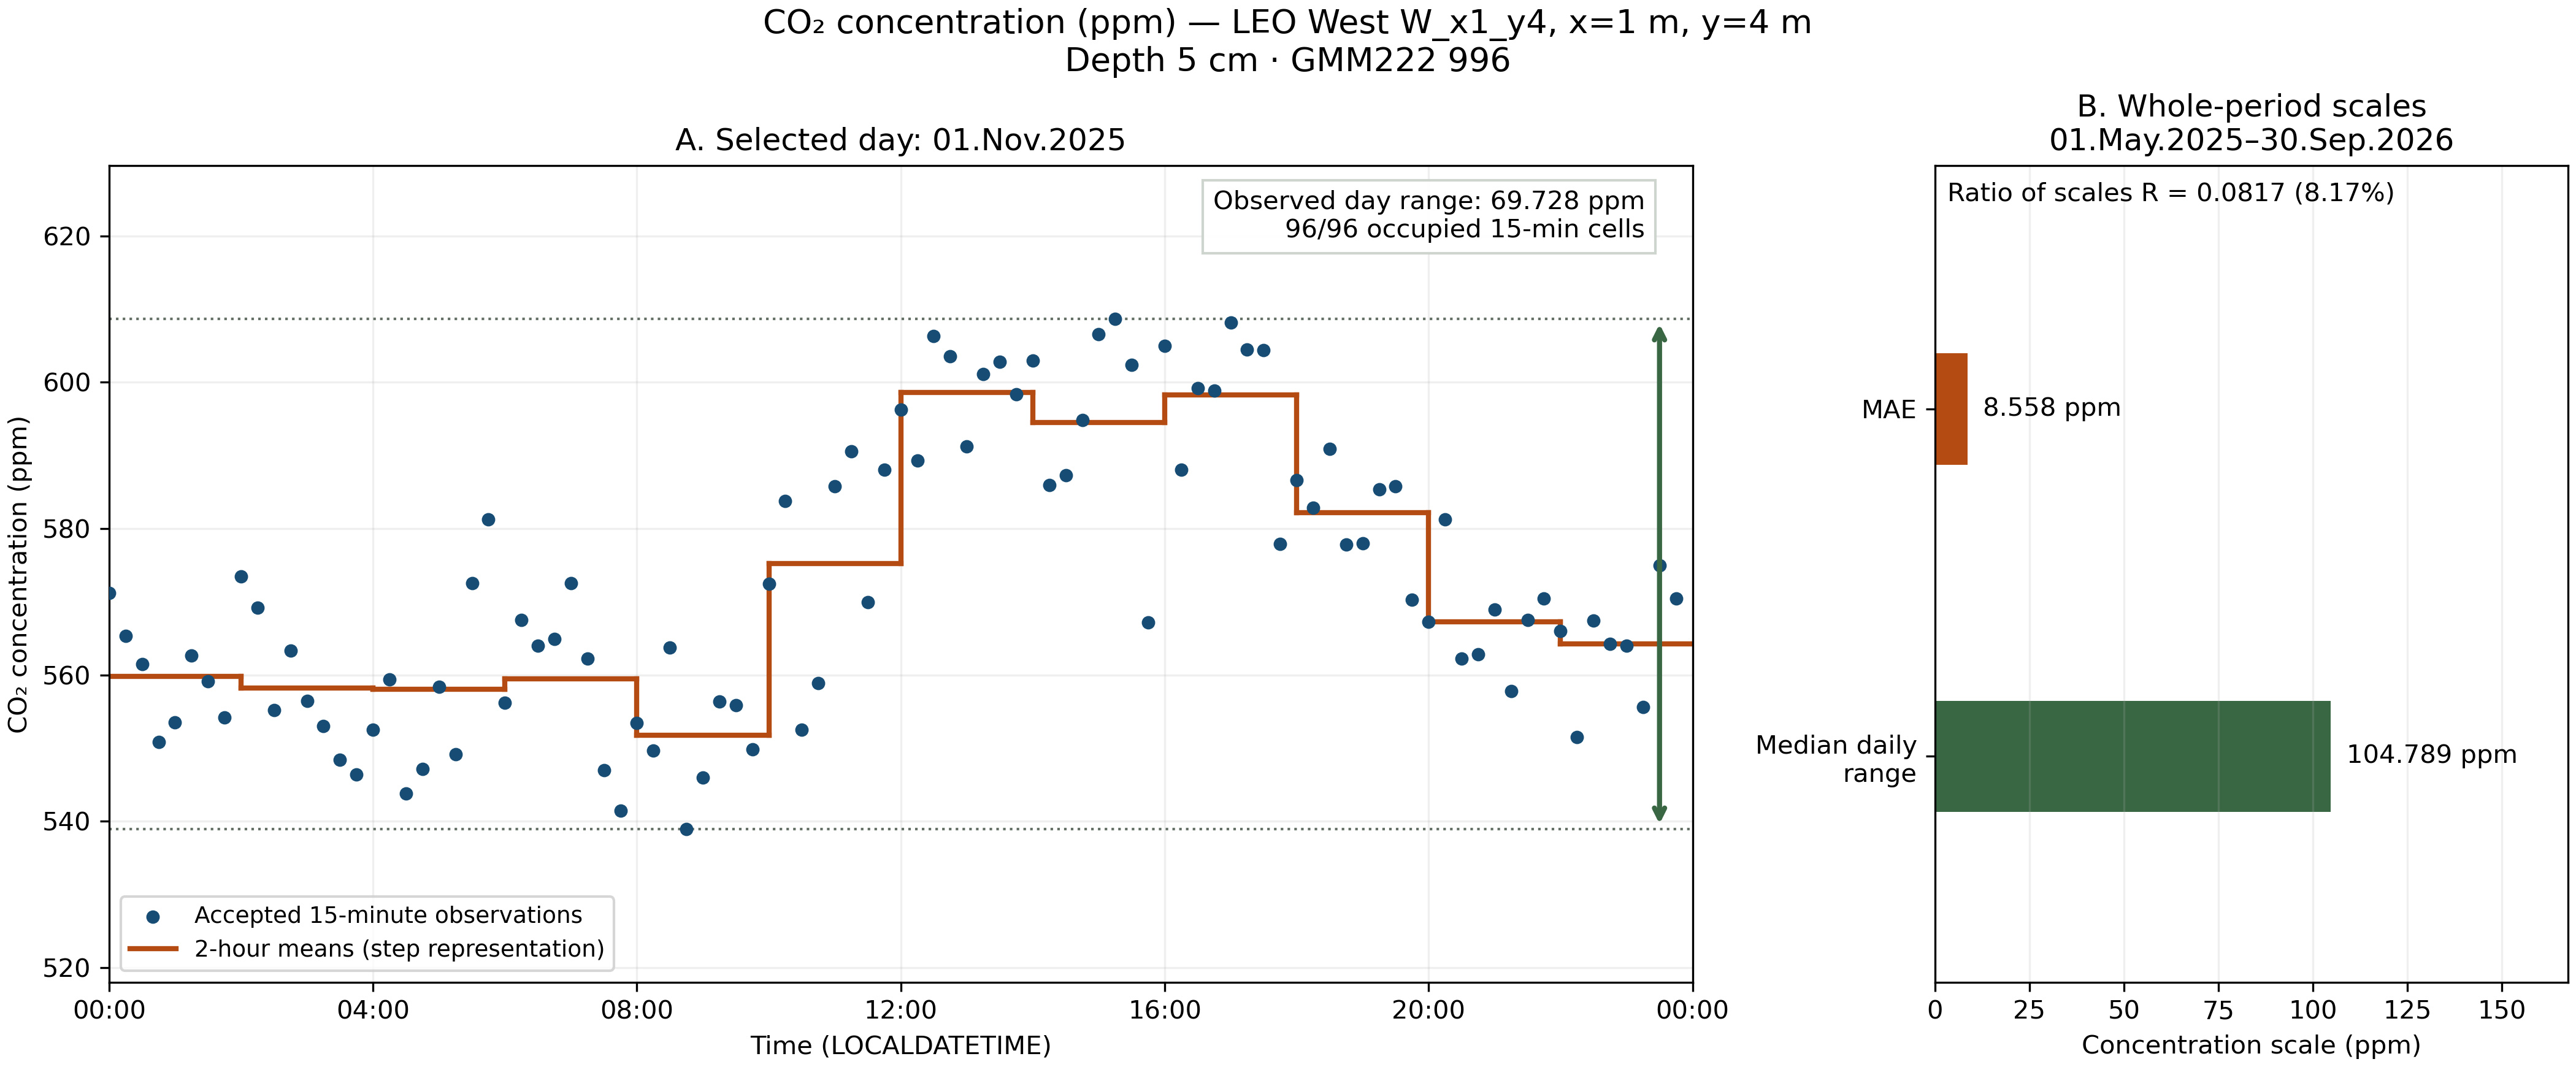

In [5]:
figure('daily_scale/daily_scale_5cm')

**Рисунок 2а.** На левой панели A я показываю исходные концентрации за 01.11.2025 синими точками и соответствующие двухчасовые средние оранжевой ступенчатой линией. Горизонтальные участки относятся к своим двухчасовым ячейкам; вертикальные соединения обозначают смену среднего, а не измеренный скачок. По рассеянию точек вокруг ступеней я вижу, какие отклонения сглаживает усреднение. Зелёная стрелка между пунктирными уровнями минимума и максимума показывает **наблюдаемый размах именно выбранного дня — 69.727882 ppm** (минимум 538.943434 ppm, максимум 608.671316 ppm).

На правой панели B я сопоставляю две масштабные линейки в ppm **за весь период 01.05.2025–30.09.2026**: оранжевую для глобального MAE **8.558477 ppm** и зелёную для медианного суточного размаха **104.788717 ppm**. Эти статистики я не привязываю к конкретному моменту выбранного дня. Их отношение равно **0.081674**, или около **8.17%**. Это придаёт среднему отклонению от двухчасового представления масштаб: оно меньше характерного наблюдаемого размаха календарного дня, но усреднение сохраняет не все внутридвухчасовые детали и экстремумы. Из такого сравнения я не заключаю, что потеряно ровно 8.17% суточной изменчивости, и не устанавливаю порог достаточности временной сетки. [JPG для печати](output/temporal_resolution_15min_vs_2h/daily_scale/daily_scale_5cm.jpg).

**Для обсуждения с I.G.** На глубине 5 см MAE двухчасового представления составляет около 8.17% медианного наблюдаемого суточного размаха; на глубинах 20 и 50 см соответствующие отношения равны около 11.96% и 14.34%. Сопоставление полных и неполных дней даёт приведённые выше изменения этих оценок масштаба. Я использую их как описательный контекст к MAE и сохраняю исходные 15-минутные данные для исследования внутридвухчасовой динамики. Само это отношение не доказывает достаточность сетки для всех фазовых окон.

[Сводная таблица](output/temporal_resolution_15min_vs_2h/daily_scale/daily_summary.csv) · [паспорт дополнения](output/temporal_resolution_15min_vs_2h/daily_scale/passport.json) · [проверки](output/temporal_resolution_15min_vs_2h/daily_scale/validation.json).

## 4. Сравнение Fourier-фаз в 14-суточных окнах

Я фиксирую **48,463 общие занятые 15-минутные ячейки**, каждая из которых содержит ровно одно принятое исходное наблюдение каждого датчика. На этом наборе я вычисляю оценку для мелкой сетки и исключительно из тех же наблюдений формирую двухчасовые средние. Маску доступности атмосферных наблюдений я не применяю. В каждом сравнении фаз я использую одно и то же 14-суточное календарное окно, от **[01.05, 15.05.2025)** до **[17.09, 01.10.2026)**, сдвигая его на одни сутки.

Я сохраняю принятое представление времени центрами календарных ячеек: для мелкой сетки это начало ячейки плюс 7 мин 30 с, для грубой — начало двухчасовой ячейки плюс 1 ч. Фактические исходные временные метки в сохранённой таблице наблюдений не изменяю. Если окно содержит N занятых мелких ячеек и K занятых крупных ячеек, каждое наблюдение на мелкой сетке имеет вес 1/N до вычитания среднего; в крупной ячейке с n наблюдениями вклад каждого из них имеет вес 1/(K n). Для каждого представления я использую его собственное среднее по окну с равными весами ячеек. **Таким образом, сравнение включает усреднение, изменение временных координат и изменение весов при неизменном составе исходных наблюдений.**

Для разрешения $h$ я сохраняю прямой комплексный коэффициент и соглашение о знаке:

$$F_j^{(h)}(W)=\frac{1}{N_h}\sum_{k\in I_h(W)}
\left(x_{j,k}^{(h)}-\overline x_{j,W}^{(h)}\right)e^{-2\pi i f_0(t_k^{(h)}-t_{\rm ref})},
\qquad f_0=1\ \mathrm{cycle/day},$$

$$\Delta\phi_{u\to v}^{(h)}(W)=\mathrm{wrap}\!\left[\mathrm{Arg}\left(F_u^{(h)}\overline{F_v^{(h)}}\right)\right],
\qquad \mathrm{wrap}(a)=(a+\pi)\bmod 2\pi-\pi.$$

Здесь я обозначаю через $W$ календарное окно, через $j$ — канал, через $I_h(W)$ — множество индексов занятых общих ячеек при разрешении $h$, а через $N_h$ — число этих ячеек. Величина $x_{j,k}^{(h)}$ — концентрация в соответствующем представлении, $\overline x_{j,W}^{(h)}$ — её арифметическое среднее по этим ячейкам, $t_k^{(h)}$ — время центра ячейки. Частоту $f_0$ сохраняю равной 1 цикл/сутки. Время в показателе экспоненты выражаю в сутках с неизменной точкой отсчёта **29.04.2025 00:00**. Через $i$ обозначаю мнимую единицу, чертой над комплексным коэффициентом — комплексное сопряжение, через $\mathrm{Arg}$ — аргумент, а через $\mathrm{wrap}$ — приведение угла к выбранной ветви. Индексы $u$ и $v$ обозначают верхний и нижний каналы пары. Положительная относительная фаза соответствует запаздыванию нижнего канала для идеальных синусоид; я не отождествляю её с измеренным физическим временем переноса.

Для двух пар глубин я вычисляю

$$\delta(W)=\mathrm{wrap}\!\left[\mathrm{Arg}\left(e^{i[\Delta\phi_{15}(W)-\Delta\phi_{120}(W)]}\right)\right],\qquad
\mathrm{MAE}_{\phi}=\frac{1}{M}\sum_W|\delta(W)|.$$

Через $\Delta\phi_{15}(W)$ и $\Delta\phi_{120}(W)$ я обозначаю относительную фазу одной и той же пары в одном окне на сетках 15 и 120 минут. Величина $\delta(W)$ — их циклическая разность, $M$ — число сопоставимых окон, а $\mathrm{MAE}_{\phi}$ — среднее абсолютное циклическое расхождение по этим окнам.

Я использую радианы на ветви $[-\pi,\pi)$ и сохраняю неопределённые фазы как пропуски, не вводя нового порога малой амплитуды. Здесь сопоставимы все **505 окон для каждой пары**. Перекрывающиеся окна зависимы; приведённые ниже квантили я использую как описательные характеристики, а не как доверительные интервалы или критерий допуска. В таблице Pair означает пару глубин, Windows — число сопоставимых окон; Median, p95 и Max обозначают медиану, 95-й процентиль и максимум модуля циклической разности, а rad — радианы.

In [4]:
display(phase_summary.assign(Pair=['5 → 20 cm', '20 → 50 cm'])[
    ['Pair', 'comparable_windows', 'MAE_rad', 'median_abs_rad', 'p95_abs_rad', 'max_abs_rad']]
    .rename(columns={'comparable_windows':'Windows', 'MAE_rad':'MAE (rad)',
        'median_abs_rad':'Median |δ| (rad)', 'p95_abs_rad':'p95 |δ| (rad)',
        'max_abs_rad':'Max |δ| (rad)'}).round(6))

,Pair,Windows,MAE (rad),Median |δ| (rad),p95 |δ| (rad),Max |δ| (rad)
0,5 → 20 cm,505,0.022320,0.015473,0.077820,0.119727
1,20 → 50 cm,505,0.086169,0.058173,0.250958,0.672526


## 5. Графики и интерпретация

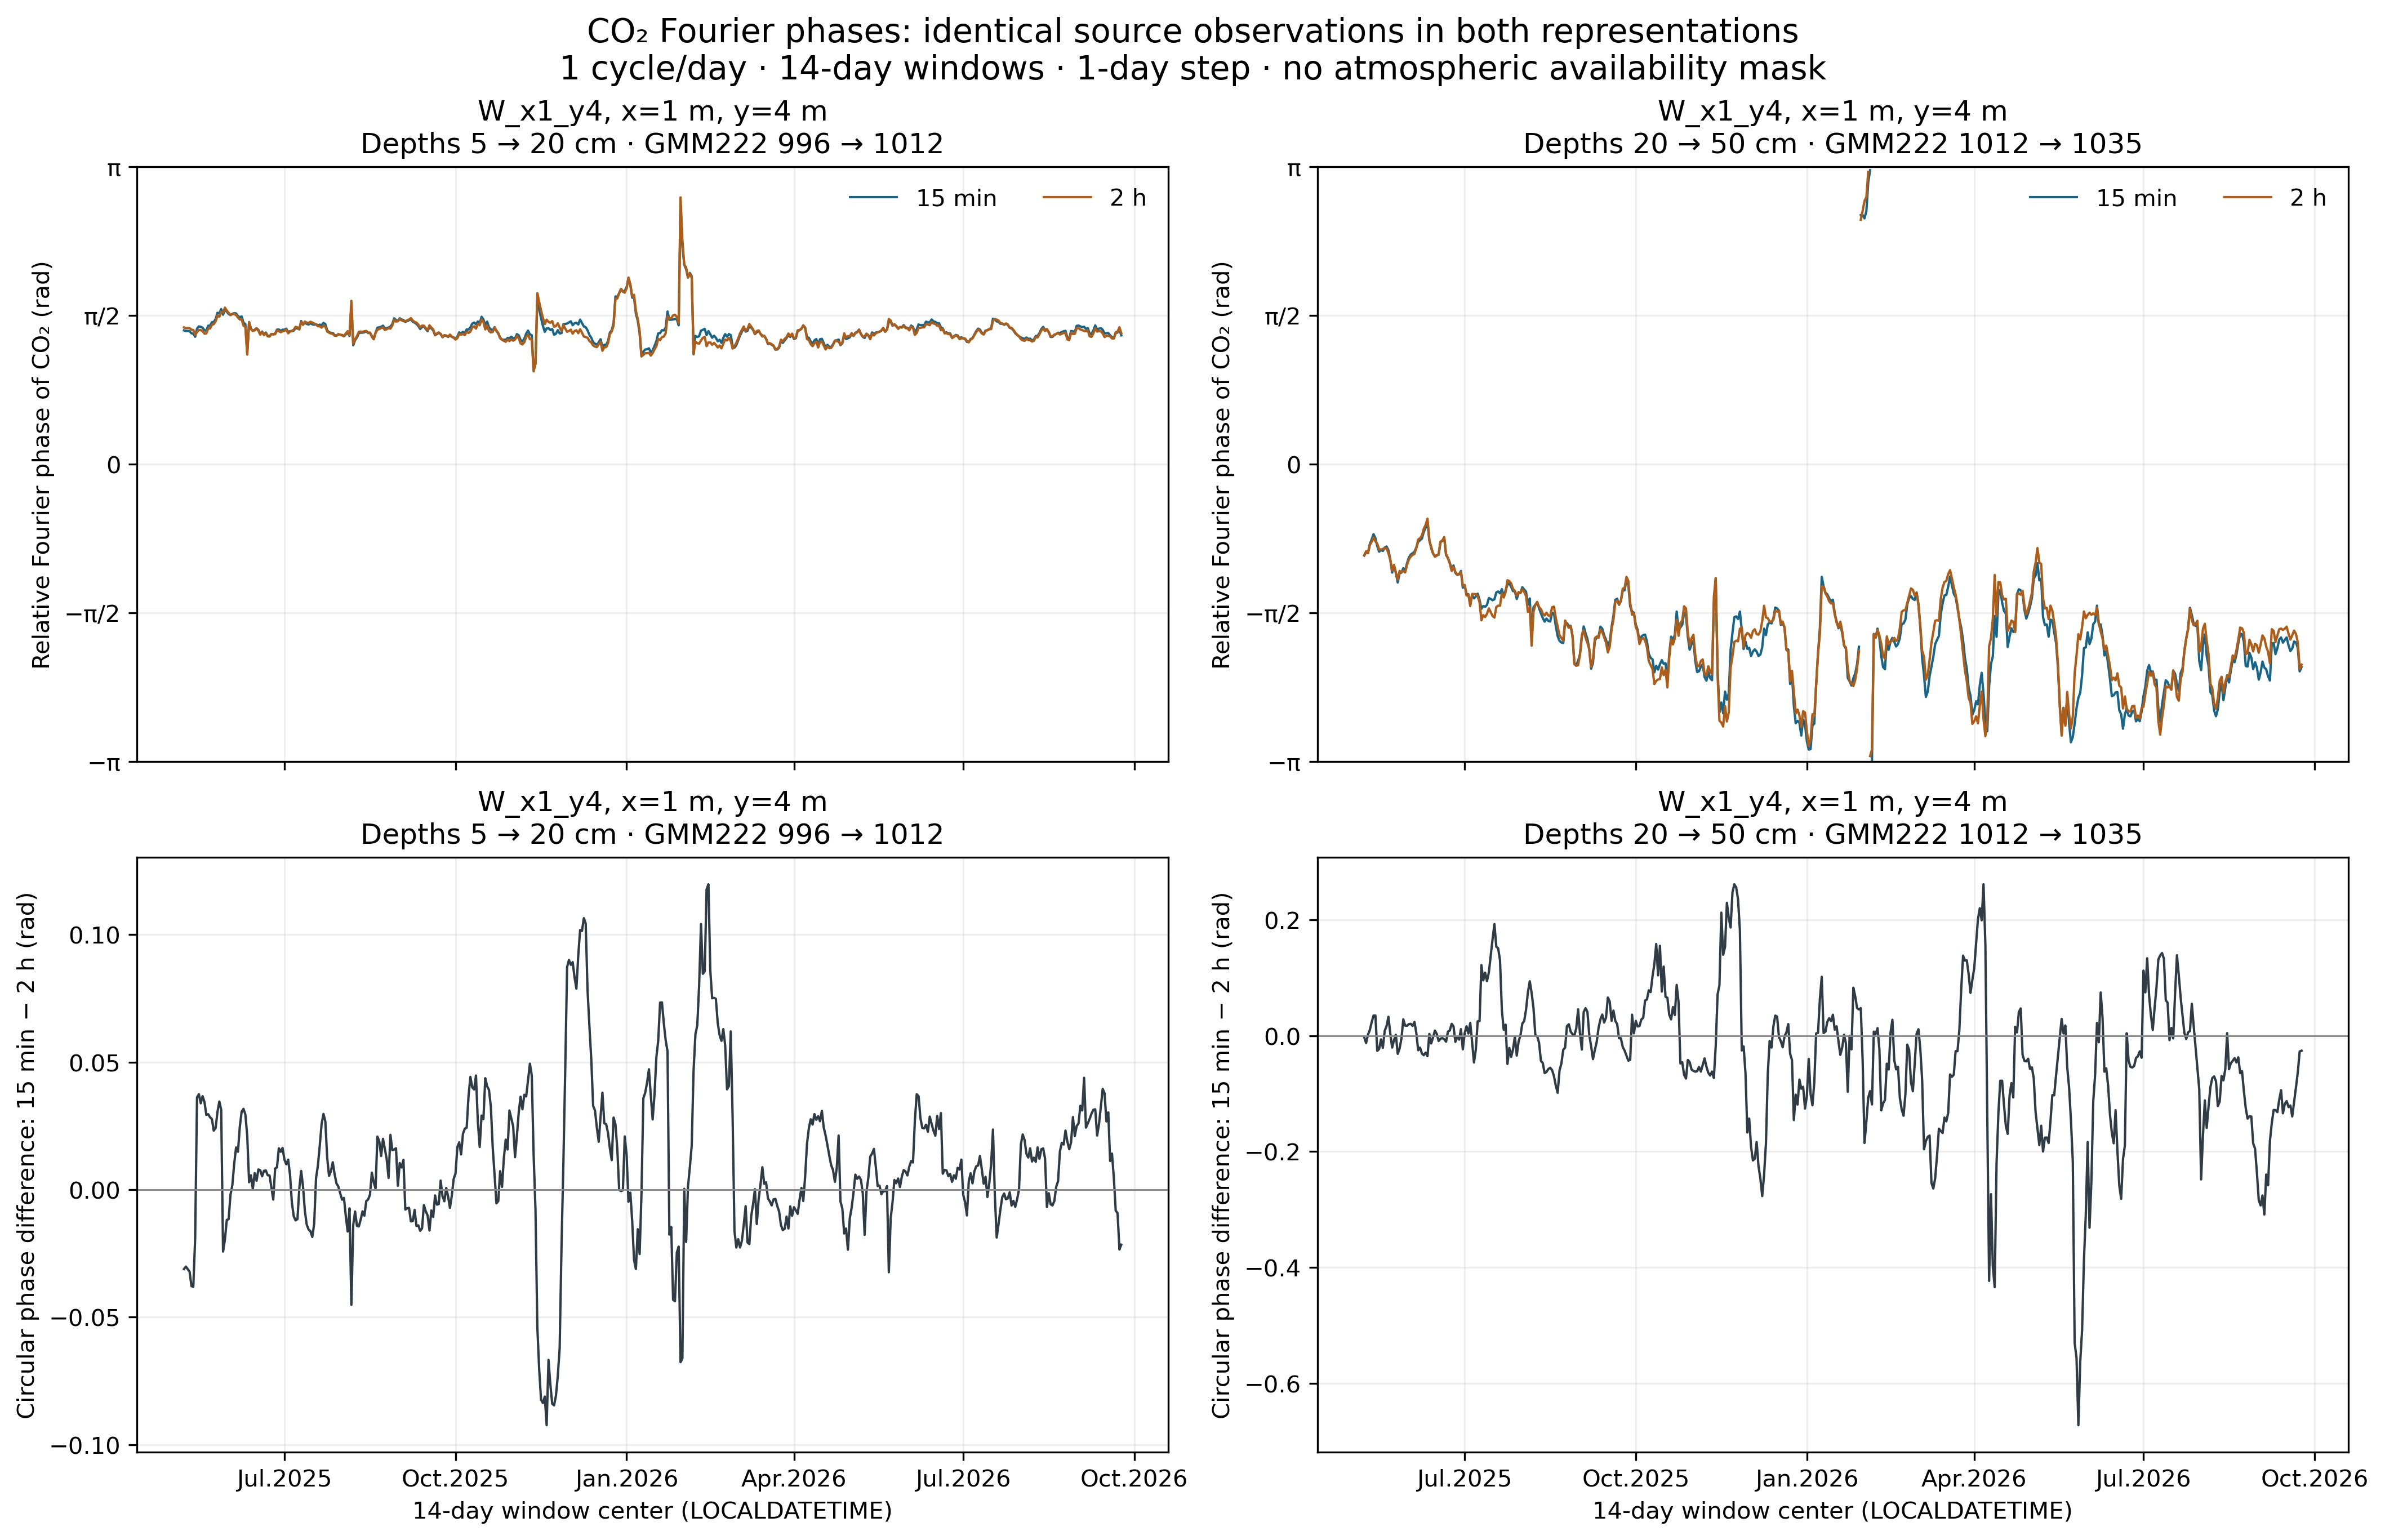

In [5]:
figure('phase_comparison_14d')

**Рисунок 3.** В левом столбце я показываю пару 5→20 см, в правом — 20→50 см. На верхних панелях я сопоставляю две оценки относительной фазы, полученные на сетках 15 минут и 2 часа; на нижних — их циклическую разность. По горизонтали я откладываю центр 14-суточного окна. Я разрываю линии при пересечении границы ветви фазы; эти разрывы отображения не означают пропусков измеренной концентрации. Нижние панели имеют разные вертикальные масштабы. По верхним панелям я оцениваю совпадение общей временной картины, а по нижним — величину расхождений в отдельных окнах. Более выраженные отклонения справа показывают, почему вывод для 5→20 см нельзя автоматически переносить на 20→50 см и почему среднего расхождения недостаточно. [JPG для печати](output/temporal_resolution_15min_vs_2h/phase_comparison_14d.jpg).

**Вывод по фазам.** Для 5→20 см я получаю MAE **0.022320 рад (0.007105π)** и максимум **0.119727 рад** в окне **[07.02, 21.02.2026)**. Для 20→50 см я получаю MAE **0.086169 рад (0.027428π)** и максимум **0.672526 рад (около 0.214π)** в окне **[20.05, 03.06.2026)**. Последний максимум существенно больше среднего; одно среднее скрыло бы чувствительность оценки в этом конкретном окне.

Я проверил модули коэффициентов и покрытие в обоих окнах максимумов. В первом окне модули на глубинах 5/20 см равны **10.229/2.847 ppm** на мелкой сетке и **10.310/2.868 ppm** на грубой; заняты **1303/1344** мелких ячеек. Во втором окне модули на глубинах 20/50 см равны **4.612/0.305 ppm** и **4.566/0.373 ppm** соответственно; заняты **1314/1344** мелких ячеек. В обоих окнах заняты **168/168** крупных ячеек. Меньший модуль коэффициента на глубине 50 см сопутствует большему фазовому расхождению; это согласуется с чувствительностью аргумента, но не устанавливает причину расхождения или неопределённость измерения. Я не ввожу порог по модулю и не исключаю эти окна.

По всем окнам покрытие мелкой сетки составляет **1285–1327 из 1344** ячеек; во всех окнах грубой сетки заняты **168 ячеек**. Занятость крупных ячеек не означает полноты исходных наблюдений. Полную диагностическую таблицу я сохраняю отдельно от основного изложения.

## 6. Моя рекомендация для I.G.

**Вопрос I.G.:** достаточно ли двухчасового разрешения для исследования относительных Fourier-фаз CO₂?

**Моя рекомендация:** я предлагаю сохранить **двухчасовую сетку как рабочее представление для совместного четырёхканального обзора фаз на суточной частоте**, с **окнами 14 суток и шагом 1 сутки**, сохраняя исходные 15-минутные подземные наблюдения и используя их фазовые оценки как опорные при интерпретации отдельных подземных окон. Для исследования динамики внутри ячеек я не рекомендую заменять исходные записи средними.

**Моё обоснование:** рисунки 1–2 количественно показывают потерю детализации концентрации: MAE **8.558 / 7.875 / 6.975 ppm**, RMSE **10.974 / 9.921 / 8.745 ppm** на глубинах 5 / 20 / 50 см. На рисунке 3 средние абсолютные расхождения фаз равны **0.022320 / 0.086169 рад** для двух пар при одинаковых исходных наблюдениях. Эти средние поддерживают выбор двухчасовой сетки для рабочего обзора, но максимум **0.672526 рад** для 20→50 см не позволяет мне утверждать равномерное согласие в каждом окне. Я сохраняю и показываю это расхождение вместе с опорной оценкой, не считая грубую оценку взаимозаменяемой с ней.

**Область применимости и ограничения:** численные результаты непосредственно охватывают только две подземные пары, принятый интервал и суточную частоту. Они не измеряют ошибку относительно истинной фазы, не устанавливают физическую значимость и не доказывают приемлемую границу ошибки. Я не могу сравнить атмосферную пару при разрешении 15 минут, поскольку такой измеренный атмосферный ряд отсутствует. Четырёхканальная маска также меняет состав используемых наблюдений; её влияние при окне 14 суток здесь не оценено количественно. Поэтому моя рекомендация для совместного обзора — практический предварительный выбор на основе доступного общего временного масштаба, непосредственно подкреплённый результатами для подземной части, **а не завершённая проверка всех трёх разностей фаз четырёхканального анализа**. Я не восстанавливаю атмосферные измерения и не делаю выводов о переносе или диффузии.

**Просьба к I.G.:** прошу оценить, обосновывают ли эти результаты с указанными ограничениями предлагаемый рабочий выбор, и утвердить либо отклонить мою рекомендацию. До этого рассмотрения я сохраняю этап 0.5 открытым; главу 1 и более широкий пересчёт не начинаю.

## 7. Краткие ссылки для воспроизводимости

Я сохраняю первоначальные 30-суточные расчёты и прежнюю внутридвухчасовую диагностику. Этот notebook читает сохранённые новые результаты; анализ и узкие синтетические тесты находятся в существующем Python-коде, а технические подробности отделены от научного обоснования.

- [Сводка по концентрации](output/temporal_resolution_15min_vs_2h/concentration_summary.csv) · [все остатки в исходные моменты наблюдений, CSV.gz](output/temporal_resolution_15min_vs_2h/concentration_residuals.csv.gz).
- [Сводка по фазам](output/temporal_resolution_15min_vs_2h/phase_summary.csv) · [все сопоставленные окна](output/temporal_resolution_15min_vs_2h/phase_comparison.csv) · [диагностика максимальных расхождений](output/temporal_resolution_15min_vs_2h/phase_extrema_diagnostics.csv).
- [Фиксированный набор исходных наблюдений и фактические времена, CSV.gz](output/temporal_resolution_15min_vs_2h/matched_source_observations.csv.gz) · [его двухчасовые агрегаты, CSV.gz](output/temporal_resolution_15min_vs_2h/matched_grid_2h.csv.gz).
- [Происхождение данных, веса, координаты и подписи рисунков](output/temporal_resolution_15min_vs_2h/passport.json) · [проверки](output/temporal_resolution_15min_vs_2h/validation.json) · [реализация](../sensorDB/preliminary_fourier_phases.py) · [тесты](../sensorDB/tests/test_preliminary_fourier_phases.py).
- [Принятые данные и ограничения](details/02_data_checks.md) · [план](PLAN.md) · [навигация по исследованию](README.md).

Специальная команда воспроизведения только этого сравнения документирована в реализации параметром `--temporal-resolution-14d`. Я не пересчитывал исторические исследования и не собирал LaTeX-отчёт.